# EMQA_L1_decomp_load

**Decomposition of Romanian monthly load: classical vs STL**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_decomp_load/EMQA_L1_decomp_load.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Monthly mean Romanian load (GW) with the classical 2x12 centred moving-average trend and the STL trend (top), and the classical and STL seasonal components (bottom); prints the classical seasonal indices and the STL seasonal amplitude in the first and the last full year.

**Data:** 2016-01 to 2025-12, monthly mean load. **Source:** energy-charts.info (Fraunhofer ISE); ENTSO-E (Transelectrica data for Romania).

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MON1 = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# Romanian generation by source and load, hourly mean MW (UTC, interval start)
GH = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
GH = GH.loc[GH.index < END_UTC]

data cut-off: 2026-10-31


## Computation

In [4]:
from statsmodels.tsa.seasonal import STL, seasonal_decompose
fy1 = Y - 1                                                     # last full year
lm = GH['load'].resample('MS').mean()
lm.index = lm.index.tz_localize(None)
lm = (lm.loc['2016-01-01':f'{fy1}-12-01'] / 1000).asfreq('MS')    # GW
w = np.r_[1 / 24, np.repeat(1 / 12, 11), 1 / 24]                # 2x12 centred moving average
cma = lm.rolling(13, center=True).apply(lambda v: float(np.dot(v, w)), raw=True)
raw_idx = (lm - cma).groupby(lm.index.month).mean()
sidx = raw_idx - raw_idx.mean()                                 # classical seasonal indices, sum to zero
sd_ = seasonal_decompose(lm, model='additive', period=12)
stl = STL(lm, period=12, seasonal=13, robust=True).fit()
y0s, y1s = str(lm.index[0].year), str(fy1)
show('decomp.start', 'first month', lm.index[0].strftime('%Y-%m'))
show('decomp.end', 'last month', lm.index[-1].strftime('%Y-%m'))
for m in ['Jan', 'Feb', 'May']:
    show(f'decomp.sidx.{m}', f'classical seasonal index {m}, GW', fl(sidx.loc[MON_EN.index(m) + 1], 3))
show('decomp.stl_amp_first', f'STL seasonal amplitude {y0s}, GW', fl(stl.seasonal.loc[y0s].max() - stl.seasonal.loc[y0s].min(), 2))
show('decomp.stl_amp_last', f'STL seasonal amplitude {y1s}, GW', fl(stl.seasonal.loc[y1s].max() - stl.seasonal.loc[y1s].min(), 2))

first month = 2016-01   [decomp.start]
last month = 2025-12   [decomp.end]
classical seasonal index Jan, GW = 0.686   [decomp.sidx.Jan]
classical seasonal index Feb, GW = 0.694   [decomp.sidx.Feb]
classical seasonal index May, GW = -0.65   [decomp.sidx.May]
STL seasonal amplitude 2016, GW = 1.52   [decomp.stl_amp_first]
STL seasonal amplitude 2025, GW = 1.27   [decomp.stl_amp_last]


## Chart

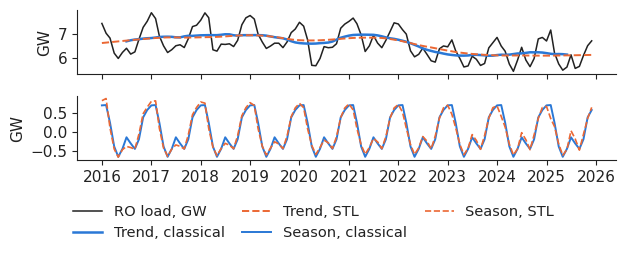

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(6.4, 2.6), sharex=True)
axs[0].plot(lm.index, lm, color='#222222', lw=1.1, label='RO load, GW')
axs[0].plot(cma.index, cma, color=PAL['RO'], lw=1.8, label='Trend, classical')
axs[0].plot(stl.trend.index, stl.trend, color=PAL['DE_LU'], lw=1.4, ls='--', label='Trend, STL')
axs[1].plot(sd_.seasonal.index, sd_.seasonal, color=PAL['RO'], lw=1.4, label='Season, classical')
axs[1].plot(stl.seasonal.index, stl.seasonal, color=PAL['DE_LU'], lw=1.2, ls='--', label='Season, STL')
for ax in axs:
    ax.set_ylabel('GW')
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.2, 1, 1))
plt.savefig('decomp_load.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()